# autoencoder_training_v7  (normal-only)

Run the cells in order. Keep `autoencoder_v7_common.py` in the same folder as these notebooks.

## Design
* The autoencoder is trained **only on BENIGN traffic**. This notebook never loads any attack data: no calibration split, no attack-based model selection.
* The configuration is **fixed in advance** (Option A), so nothing is tuned on attacks.
* **Decision rule:** reconstruction error (MSE) above the threshold -> **UNKNOWN**, otherwise **NORMAL**. The threshold is a percentile of benign *validation* errors (3% false-positive rate by default).
* The fixed configuration comes from the best repeated performer in the v5/v6 experiments: 48-24 hidden units, 12-unit linear bottleneck, MSE loss, signed-log scaling and engineered port features (port rarity learned from benign training data). Three seeds are averaged to reduce run-to-run variance.

## 1. Imports, paths and fixed configuration

In [1]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from autoencoder_v7_common import (VERSION, FEATURES, LABELS, validate_frame, fit_preprocessing, transform,
                                   reconstruction_mse, benign_threshold)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
PROJECT_ROOT = Path('..')  # Adjust to match your project layout
DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'Data_V2'
TRAIN_FILE = DATA_DIR / 'autoencoder_benign_train.parquet'
VAL_FILE = DATA_DIR / 'autoencoder_benign_validation.parquet'
MODEL_DIR = PROJECT_ROOT / 'saved-models' / f'autoencoder_{VERSION}'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results' / f'autoencoder_{VERSION}'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- Fixed configuration (decided before looking at any attack result) ----
HIDDEN = (48, 24)
LATENT = 12
ENSEMBLE_SEEDS = [42, 43, 44]
FPR_OPTIONS = [0.01, 0.03, 0.05]
TARGET_FPR = 0.03             # threshold = 97th percentile of benign validation errors
EPOCHS = 100; BATCH_SIZE = 1024; PRED_BATCH_SIZE = 4096
QUICK_RUN = False             # True = tiny smoke test
if QUICK_RUN: ENSEMBLE_SEEDS = [42, 43]; EPOCHS = 3
assert TARGET_FPR in FPR_OPTIONS
for p in (TRAIN_FILE, VAL_FILE):
    if not p.exists(): raise FileNotFoundError(p.resolve())
print('Version:', VERSION, '| labels:', LABELS, '| config:', HIDDEN, LATENT, 'seeds', ENSEMBLE_SEEDS)

Version: v7 | labels: ('NORMAL', 'UNKNOWN') | config: (48, 24) 12 seeds [42, 43, 44]


## 2. Load benign training and validation data (benign-only is enforced)

In [2]:
train_df, X_train = validate_frame(pd.read_parquet(TRAIN_FILE), 'train', benign_only=True)
val_df, X_val = validate_frame(pd.read_parquet(VAL_FILE), 'validation', benign_only=True)
print('Train:', X_train.shape, 'Validation:', X_val.shape, '(all BENIGN)')
prep = fit_preprocessing(X_train)
xtr = transform(X_train, prep); xval = transform(X_val, prep)
print('Model input dimension after port engineering:', xtr.shape[1])

Train: (1465952, 69) Validation: (314133, 69) (all BENIGN)
Model input dimension after port engineering: 72


## 3. Train the normal-only autoencoder ensemble

In [3]:
def make_model(input_dim, hidden, latent):
    inputs = Input(shape=(input_dim,))
    x = inputs
    for units in hidden: x = Dense(units, activation='relu')(x)
    x = Dense(latent, activation='linear', name='bottleneck')(x)
    for units in reversed(hidden): x = Dense(units, activation='relu')(x)
    outputs = Dense(input_dim, activation='linear')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

models, histories = [], []
for seed in ENSEMBLE_SEEDS:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    model = make_model(xtr.shape[1], HIDDEN, LATENT)
    history = model.fit(xtr, xtr, validation_data=(xval, xval), epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
        callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)])
    models.append(model); histories.append(history.history)
    print('seed', seed, '| epochs', len(history.history['loss']), '| best val loss %.5f' % min(history.history['val_loss']))


seed 42 | epochs 100 | best val loss 0.01112
seed 43 | epochs 100 | best val loss 0.00822
seed 44 | epochs 100 | best val loss 0.01046


## 4. Benign-only threshold

Scores are the seed-averaged reconstruction MSE of the benign validation set. The threshold is its `1 - FPR` percentile, so about `TARGET_FPR` of unseen normal traffic will be labelled UNKNOWN by design.

In [4]:
val_scores = reconstruction_mse(models, xval, PRED_BATCH_SIZE)
thresholds = {f: benign_threshold(val_scores, f) for f in FPR_OPTIONS}
train_scores = reconstruction_mse(models, xtr[:200_000], PRED_BATCH_SIZE)
print('Benign validation MSE  median=%.5f  p95=%.5f  p99=%.5f' % tuple(np.percentile(val_scores, [50, 95, 99])))
print('Benign train MSE (200k) median=%.5f  p97=%.5f' % (np.median(train_scores), np.percentile(train_scores, 97)))
for f, t in thresholds.items(): print(f'FPR {f:.0%} -> threshold {t:.6f}')
print('Share of validation flows labelled UNKNOWN at target threshold: %.4f' % np.mean(val_scores > thresholds[TARGET_FPR]))

Benign validation MSE  median=0.00243  p95=0.03716  p99=0.10573
Benign train MSE (200k) median=0.00239  p97=0.05073
FPR 1% -> threshold 0.105728
FPR 3% -> threshold 0.050959
FPR 5% -> threshold 0.037157
Share of validation flows labelled UNKNOWN at target threshold: 0.0300


## 5. Save artifacts and training curve

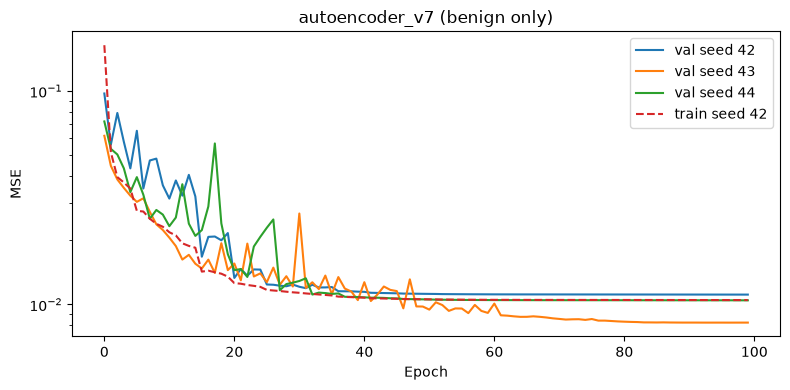

{
  "version": "v7",
  "design": "normal-only autoencoder; reconstruction error above threshold -> UNKNOWN",
  "labels": [
    "NORMAL",
    "UNKNOWN"
  ],
  "hidden": [
    48,
    24
  ],
  "latent": 12,
  "loss": "mse",
  "score": "mse",
  "port_mode": "engineered",
  "seeds": [
    42,
    43,
    44
  ],
  "target_fpr": 0.03,
  "threshold": 0.05095853030681598,
  "thresholds": {
    "0.01": 0.10572802394628475,
    "0.03": 0.05095853030681598,
    "0.05": 0.03715727180242536
  },
  "threshold_source": "benign validation percentile only",
  "model_files": [
    "autoencoder_v7_model_seed42.keras",
    "autoencoder_v7_model_seed43.keras",
    "autoencoder_v7_model_seed44.keras"
  ]
}
Model artifacts: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\saved-models\autoencoder_v7


In [5]:
selection = {'version': VERSION, 'design': 'normal-only autoencoder; reconstruction error above threshold -> UNKNOWN',
             'labels': list(LABELS), 'hidden': list(HIDDEN), 'latent': LATENT, 'loss': 'mse', 'score': 'mse',
             'port_mode': prep['port_mode'], 'seeds': ENSEMBLE_SEEDS, 'target_fpr': TARGET_FPR,
             'threshold': thresholds[TARGET_FPR], 'thresholds': {str(f): t for f, t in thresholds.items()},
             'threshold_source': 'benign validation percentile only',
             'model_files': [f'autoencoder_{VERSION}_model_seed{s}.keras' for s in ENSEMBLE_SEEDS]}
for m, fname in zip(models, selection['model_files']): m.save(MODEL_DIR / fname)
joblib.dump(prep, MODEL_DIR / f'autoencoder_{VERSION}_preprocessing.joblib')
(MODEL_DIR / f'autoencoder_{VERSION}_selection.json').write_text(json.dumps(selection, indent=2))
(RESULTS_DIR / f'autoencoder_{VERSION}_training_histories.json').write_text(
    json.dumps([{k: list(map(float, v)) for k, v in h.items()} for h in histories], indent=2))
plt.figure(figsize=(8, 4))
for s, h in zip(ENSEMBLE_SEEDS, histories): plt.plot(h['val_loss'], label=f'val seed {s}')
plt.plot(histories[0]['loss'], '--', label=f'train seed {ENSEMBLE_SEEDS[0]}')
plt.legend(); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.yscale('log'); plt.title(f'autoencoder_{VERSION} (benign only)'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_loss_curve.png', dpi=150); plt.show()
print(json.dumps(selection, indent=2)); print('Model artifacts:', MODEL_DIR.resolve())